In [1]:
from google.colab import files  # Imports the file-upload utility for Google Colab
uploaded = files.upload()  # Opens a dialog to upload insurance_pre(1).csv

Saving insurance_pre.csv to insurance_pre.csv


In [2]:
%pip install -q xgboost  # Installs the XGBoost library required for the third model

import pandas as pd  # Imports pandas for reading and processing the dataset
import numpy as np  # Imports NumPy for numerical calculations
import matplotlib.pyplot as plt  # Imports Matplotlib for visualizing model scores

from sklearn.model_selection import train_test_split  # Imports the function to split training and testing data
from sklearn.compose import ColumnTransformer  # Imports a tool for preprocessing different column types
from sklearn.preprocessing import OneHotEncoder  # Imports a tool to convert categorical text into numeric features
from sklearn.pipeline import Pipeline  # Imports a tool to combine preprocessing and model training
from sklearn.ensemble import AdaBoostRegressor, GradientBoostingRegressor  # Imports two boosting regression algorithms
from xgboost import XGBRegressor  # Imports the XGBoost regression algorithm
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score  # Imports regression evaluation metrics

In [3]:
filename = next(iter(uploaded))  # Retrieves the name of the uploaded CSV file
df = pd.read_csv(filename)  # Reads the uploaded CSV file into a DataFrame

print("Dataset shape:", df.shape)  # Displays the number of rows and columns
print(df.head())  # Displays the first five records
print(df.isnull().sum())  # Checks for missing values in each column
print(df.dtypes)  # Displays the data type of every column

Dataset shape: (1338, 6)
   age     sex     bmi  children smoker      charges
0   19  female  27.900         0    yes  16884.92400
1   18    male  33.770         1     no   1725.55230
2   28    male  33.000         3     no   4449.46200
3   33    male  22.705         0     no  21984.47061
4   32    male  28.880         0     no   3866.85520
age         0
sex         0
bmi         0
children    0
smoker      0
charges     0
dtype: int64
age           int64
sex          object
bmi         float64
children      int64
smoker       object
charges     float64
dtype: object


In [4]:
X = df.drop("charges", axis=1)  # Selects all columns except charges as input features
y = df["charges"]  # Selects charges as the numerical target to predict

categorical_cols = ["sex", "smoker"]  # Identifies the categorical text columns
numerical_cols = ["age", "bmi", "children"]  # Identifies the numerical input columns

print("Input features:", X.columns.tolist())  # Displays the selected input feature names
print("Target variable: charges")  # Displays the target variable name

Input features: ['age', 'sex', 'bmi', 'children', 'smoker']
Target variable: charges


In [5]:
X_train, X_test, y_train, y_test = train_test_split(  # Splits input features and target values together
    X, y, test_size=0.20, random_state=42  # Uses 80% for training and 20% for testing with a fixed random seed
)  # Completes the train-test split

print("Training records:", len(X_train))  # Displays the number of training records
print("Testing records:", len(X_test))  # Displays the number of testing records

Training records: 1070
Testing records: 268


In [6]:
preprocessor = ColumnTransformer([  # Creates a preprocessing system for the input features
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_cols),  # Converts sex and smoker into numeric indicator columns
    ("numerical", "passthrough", numerical_cols)  # Keeps age, bmi, and children as numerical values
])  # Finishes the preprocessing configuration

In [7]:
models = {  # Creates a dictionary containing the three boosting models

    "AdaBoost": AdaBoostRegressor(  # Creates the AdaBoost regression model
        n_estimators=100,  # Uses 100 sequential estimators
        learning_rate=0.05,  # Controls the contribution of each estimator
        random_state=42  # Makes the experiment reproducible
    ),  # Finishes the AdaBoost model definition

    "Gradient Boosting": GradientBoostingRegressor(  # Creates the Gradient Boosting regression model
        n_estimators=100,  # Builds 100 boosting stages
        learning_rate=0.05,  # Controls the contribution of each boosting stage
        max_depth=3,  # Limits each tree to a maximum depth of three
        random_state=42  # Makes the experiment reproducible
    ),  # Finishes the Gradient Boosting model definition

    "XGBoost": XGBRegressor(  # Creates the XGBoost regression model
        n_estimators=100,  # Uses 100 boosting rounds
        learning_rate=0.05,  # Controls the contribution of each boosting round
        max_depth=3,  # Limits tree depth to help control overfitting
        objective="reg:squarederror",  # Specifies regression with squared-error loss
        eval_metric="rmse",  # Uses RMSE as the model's evaluation metric
        random_state=42,  # Makes the experiment reproducible
        n_jobs=-1  # Uses available CPU cores for training
    )  # Finishes the XGBoost model definition

}  # Finishes the dictionary of three algorithms

In [8]:
results = []  # Creates an empty list to store the evaluation results
trained_models = {}  # Creates a dictionary to save the trained models

for name, model in models.items():  # Iterates through each boosting algorithm

    pipeline = Pipeline([  # Combines preprocessing and model training
        ("preprocessing", preprocessor),  # Applies categorical encoding to the input features
        ("regressor", model)  # Adds the current boosting regression algorithm
    ])  # Finishes the pipeline definition

    pipeline.fit(X_train, y_train)  # Trains the model using the training dataset
    y_pred = pipeline.predict(X_test)  # Predicts insurance charges for the testing dataset

    mae = mean_absolute_error(y_test, y_pred)  # Calculates the average absolute prediction error
    mse = mean_squared_error(y_test, y_pred)  # Calculates the average squared prediction error
    rmse = np.sqrt(mse)  # Calculates the square root of MSE
    r2 = r2_score(y_test, y_pred)  # Measures how well predictions explain the variation in actual charges

    results.append({  # Adds the current model's scores to the results list
        "Algorithm": name,  # Stores the algorithm name
        "MAE": mae,  # Stores mean absolute error
        "MSE": mse,  # Stores mean squared error
        "RMSE": rmse,  # Stores root mean squared error
        "R2 Score": r2,  # Stores the coefficient of determination
        "R2 Percentage": r2 * 100  # Converts R2 into a percentage for presentation
    })  # Finishes storing the evaluation results

    trained_models[name] = pipeline  # Saves the trained preprocessing and regression pipeline

    print("\nAlgorithm:", name)  # Displays the current algorithm name
    print(f"MAE: {mae:.2f}")  # Displays average absolute prediction error
    print(f"MSE: {mse:.2f}")  # Displays mean squared prediction error
    print(f"RMSE: {rmse:.2f}")  # Displays root mean squared prediction error
    print(f"R2 Score: {r2:.4f}")  # Displays the R2 score to four decimal places


Algorithm: AdaBoost
MAE: 4156.60
MSE: 25810770.67
RMSE: 5080.43
R2 Score: 0.8337

Algorithm: Gradient Boosting
MAE: 2476.46
MSE: 18762442.41
RMSE: 4331.56
R2 Score: 0.8791

Algorithm: XGBoost
MAE: 2441.81
MSE: 18011015.10
RMSE: 4243.94
R2 Score: 0.8840


In [9]:
results_df = pd.DataFrame(results)  # Converts the results list into a comparison table
results_df = results_df.sort_values("R2 Score", ascending=False)  # Ranks models from highest to lowest R2 score

display(results_df.round(4))  # Displays the comparison table with four decimal places

,Algorithm,MAE,MSE,RMSE,R2 Score,R2 Percentage
2,XGBoost,2441.8062,1.801102e+07,4243.9386,0.8840,88.3986
1,Gradient Boosting,2476.4557,1.876244e+07,4331.5635,0.8791,87.9146
0,AdaBoost,4156.5952,2.581077e+07,5080.4302,0.8337,83.3746


In [10]:
best_row = results_df.iloc[0]  # Selects the model with the highest R2 score
best_name = best_row["Algorithm"]  # Retrieves the name of the best-performing model
best_r2 = best_row["R2 Score"]  # Retrieves the highest R2 score
best_rmse = best_row["RMSE"]  # Retrieves the RMSE of the best-performing model
best_mae = best_row["MAE"]  # Retrieves the MAE of the best-performing model

print("BEST BOOSTING ALGORITHM:", best_name)  # Displays the winning algorithm
print(f"R2 Score: {best_r2:.4f}")  # Displays the winning model's R2 score
print(f"R2 Percentage: {best_r2 * 100:.2f}%")  # Displays the R2 score multiplied by 100
print(f"RMSE: {best_rmse:.2f}")  # Displays the winning model's prediction error
print(f"MAE: {best_mae:.2f}")  # Displays its average absolute prediction error

BEST BOOSTING ALGORITHM: XGBoost
R2 Score: 0.8840
R2 Percentage: 88.40%
RMSE: 4243.94
MAE: 2441.81


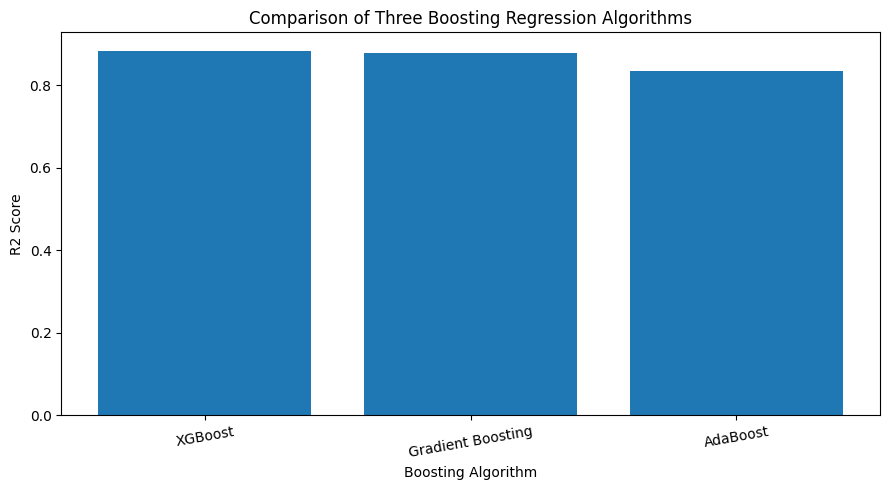

In [11]:
plt.figure(figsize=(9, 5))  # Creates a chart with a suitable width and height
plt.bar(results_df["Algorithm"], results_df["R2 Score"])  # Draws a bar for each model's R2 score
plt.xlabel("Boosting Algorithm")  # Labels the horizontal axis
plt.ylabel("R2 Score")  # Labels the vertical axis
plt.title("Comparison of Three Boosting Regression Algorithms")  # Adds the chart title
plt.xticks(rotation=10)  # Rotates the algorithm names slightly for readability
plt.tight_layout()  # Adjusts spacing to prevent labels from overlapping
plt.show()  # Displays the comparison chart

**Title: Performance Comparison of Three Boosting Algorithms for Insurance Cost Prediction**

**Objective:** To implement AdaBoost, Gradient Boosting, and XGBoost regression algorithms and compare their performance on the insurance dataset.

**Methodology:** The dataset was divided into 80% training data and 20% testing data. Categorical features were encoded, and all three models were trained using the training data. Their predictions were evaluated using MAE, MSE, RMSE, and R² score.

**Result:** The three boosting algorithms were compared using their test-set evaluation metrics. The algorithm with the highest R² score was selected as the best-performing model for this experiment.

**Conclusion:** Boosting algorithms can predict medical insurance charges from customer attributes such as age, BMI, smoking status, and number of children. The best-performing algorithm was identified by comparing the actual test scores, with RMSE and MAE used to assess prediction errors.